<a href="https://colab.research.google.com/github/Togzhan230/coffee-shop-loyalty-final/blob/main/Unsupervised_P2_Variant16_Coffee_shop_loyalty_with_references.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Project (Module 10): Unsupervised Learning
**Variant 16: Coffee shop loyalty.** Same customers and features as Module 9 (Practice 8), but **no target label is used to fit any model**.

**Object:** a coffee-shop customer. **Observation unit:** one customer (1,000 rows).
**Research question:** are there natural groups of customers, a low-dimensional structure, and unusual customers, based on `visits_per_week`, `order_price` and `wait_time`?

## 1. Imports and reproducibility

In [1]:
# References: [1][2][3][4] (full list at the end of the notebook)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(42)   # same seed as Module 9

## 2. Data: the same synthetic customers as in Module 9
UCI Online Retail (id=352) has no *wait time* and no coffee-shop visits, so, as the worksheet allows, I use **explicitly synthetic data with documented assumptions** (identical generator and seed as Module 9, so both projects use the same customers).

Assumptions: visits per week ~ Gamma, order price ~ Normal(6.5, 2.0), wait time ~ Gamma; values clipped to realistic ranges. Missing readings are simulated: 50 order prices (5 %) and 80 wait times (8 %).

The Module 9 label `returns_next_week` is generated only to keep the random stream identical to Module 9. It is stored **separately** and is **never** used to fit any model; it is used only at the very end as a post-hoc sanity check.

In [2]:
# References: [2][15][16][17] (full list at the end of the notebook)
n = 1000
df = pd.DataFrame({
    "visits_per_week": np.clip(rng.gamma(4.0, 0.7, n), 0.2, 7.0).round(1),
    "order_price": np.clip(rng.normal(6.5, 2.0, n), 2.0, 15.0).round(2),
    "wait_time": np.clip(rng.gamma(3.0, 1.6, n), 0.5, 20.0).round(1),
})

# Module 9 label: generated only to keep the random numbers identical, then set aside
z = (0.25 + 0.90 * (df["visits_per_week"] - 2.8)
     + 0.12 * (df["order_price"] - 6.5)
     - 0.22 * (df["wait_time"] - 4.8)
     - 0.15 * np.maximum(df["wait_time"] - 10, 0))
hidden_label = pd.Series((rng.random(n) < 1 / (1 + np.exp(-z))).astype(int),
                         name="returns_next_week")

for column, k in [("order_price", 50), ("wait_time", 80)]:
    df.loc[rng.choice(n, size=k, replace=False), column] = np.nan

features = ["visits_per_week", "order_price", "wait_time"]
X = df[features].copy()          # feature matrix WITHOUT any label

## 3. Inspect the data

In [3]:
# References: [3] (full list at the end of the notebook)
print("Shape:", X.shape)
print(pd.DataFrame({"feature": X.columns, "dtype": X.dtypes.astype(str).values}))
print()
print(X.head())
print()
print(X.describe().round(2))
print()
print("Missing values:")
print(X.isna().sum())

Shape: (1000, 3)
           feature    dtype
0  visits_per_week  float64
1      order_price  float64
2        wait_time  float64

   visits_per_week  order_price  wait_time
0              3.0          NaN       13.7
1              3.7         5.44        3.5
2              2.7          NaN        6.3
3              2.5         5.60        NaN
4              3.9         5.17        3.2

       visits_per_week  order_price  wait_time
count          1000.00       950.00     920.00
mean              2.75         6.58       4.79
std               1.34         1.99       2.70
min               0.30         2.00       0.50
25%               1.80         5.21       2.80
50%               2.60         6.56       4.30
75%               3.50         7.95       6.10
max               7.00        12.62      19.80

Missing values:
visits_per_week     0
order_price        50
wait_time          80
dtype: int64


## 4. Exploratory figures (3 figures)

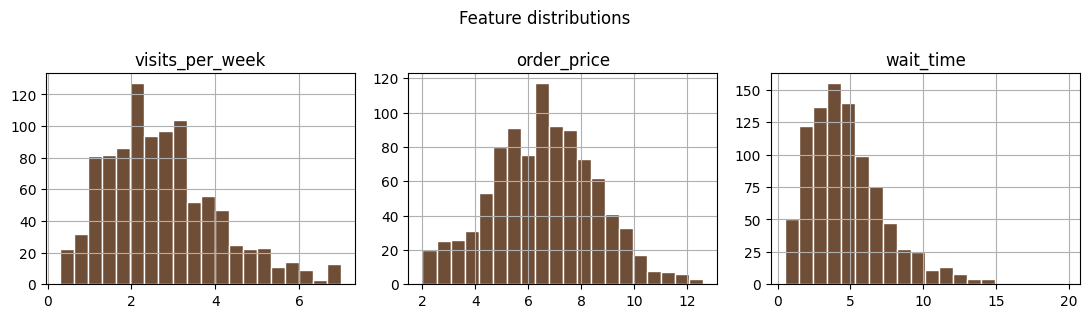

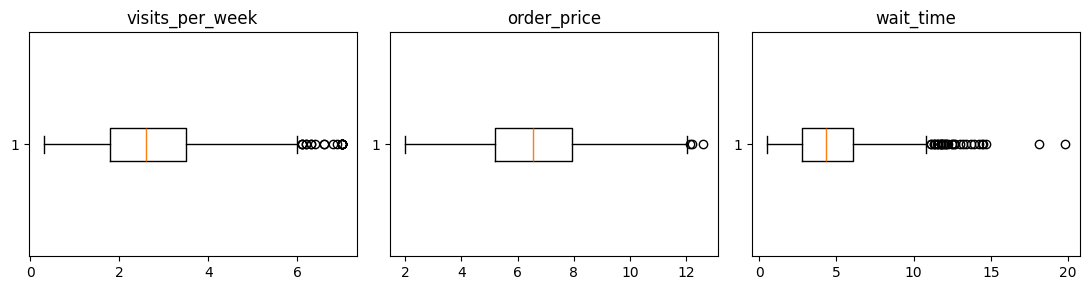

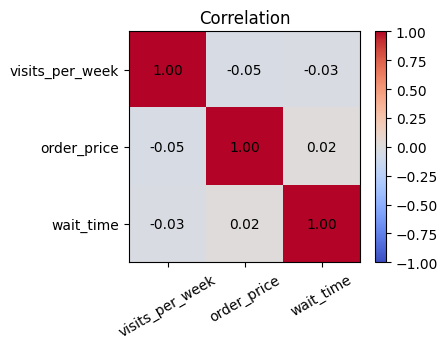

In [4]:
# References: [4] (full list at the end of the notebook)
# Figure 1: histograms
X.hist(figsize=(11, 3.2), bins=20, color="#6F4E37", edgecolor="white", layout=(1, 3))
plt.suptitle("Feature distributions"); plt.tight_layout(); plt.show()

# Figure 2: boxplots (outlier candidates)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col in zip(axes, features):
    ax.boxplot(X[col].dropna(), vert=False); ax.set_title(col)
plt.tight_layout(); plt.show()

# Figure 3: correlation heatmap
corr = X.corr()
plt.figure(figsize=(4.5, 3.6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(3), features, rotation=30); plt.yticks(range(3), features)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation"); plt.colorbar(); plt.tight_layout(); plt.show()

## 5. Preprocessing: imputation and standardization
K-Means, DBSCAN and PCA are distance/variance based, so features must be on the same scale. Missing values are filled with the **median** (robust to the skewed distributions seen above). Below I check that this choice is reasonable by comparing it with dropping incomplete rows, and I test scaling with K and `random_state` held fixed.

In [5]:
# References: [5][6][8][15] (full list at the end of the notebook)
imputer = SimpleImputer(strategy="median")
X_imp = pd.DataFrame(imputer.fit_transform(X), columns=features)

scaler = StandardScaler()
Xs = scaler.fit_transform(X_imp)
print("Scaled mean:", np.round(Xs.mean(axis=0), 3), "| std:", np.round(Xs.std(axis=0), 3))

# Imputation check: median fill vs dropping incomplete rows (K=3, fixed seed)
X_drop = X.dropna()
lab_drop = KMeans(3, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(X_drop))
lab_imp = KMeans(3, n_init=10, random_state=42).fit_predict(Xs)
print(f"Rows kept: median-fill = {len(X_imp)}, drop = {len(X_drop)}")
print("Silhouette (drop rows):  ", round(silhouette_score(StandardScaler().fit_transform(X_drop), lab_drop), 3))
print("Silhouette (median fill):", round(silhouette_score(Xs, lab_imp), 3))

# Scaling experiment: raw vs scaled
raw_lab = KMeans(3, n_init=10, random_state=42).fit_predict(X_imp)
print("Raw silhouette:   ", round(silhouette_score(X_imp, raw_lab), 3))
print("Scaled silhouette:", round(silhouette_score(Xs, lab_imp), 3))

Scaled mean: [-0. -0. -0.] | std: [1. 1. 1.]
Rows kept: median-fill = 1000, drop = 875
Silhouette (drop rows):   0.244
Silhouette (median fill): 0.258
Raw silhouette:    0.268
Scaled silhouette: 0.258


## 6. K-Means: choosing K (elbow + silhouette, K = 2…8)

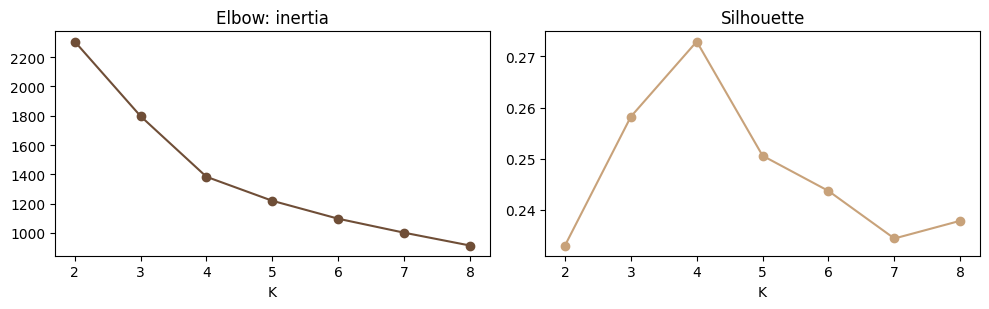

   K  inertia  silhouette
0  2   2306.7       0.233
1  3   1797.1       0.258
2  4   1383.4       0.273
3  5   1219.6       0.251
4  6   1097.2       0.244
5  7   1001.9       0.234
6  8    914.3       0.238


In [6]:
# References: [7][8][15] (full list at the end of the notebook)
ks = list(range(2, 9))
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = m.fit_predict(Xs)
    inertias.append(m.inertia_); sils.append(silhouette_score(Xs, lab))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(ks, inertias, marker="o", color="#6F4E37"); axes[0].set_title("Elbow: inertia")
axes[1].plot(ks, sils, marker="o", color="#C8A27A");   axes[1].set_title("Silhouette")
for a in axes: a.set_xlabel("K")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"K": ks, "inertia": np.round(inertias, 1), "silhouette": np.round(sils, 3)}))

In [7]:
# References: [8][15] (full list at the end of the notebook)
K = 4   # chosen after reading the table above (see justification below)
km = KMeans(n_clusters=K, n_init=10, random_state=42)
km_labels = km.fit_predict(Xs)
print(pd.Series(km_labels).value_counts().sort_index())

0    353
1    289
2    220
3    138
Name: count, dtype: int64


**Why K = 4.** Silhouette is highest at K=4 (about 0.27) and the elbow in inertia flattens after K=3–4. The result is also stable across 5 seeds (silhouette about 0.27 each time) and gives four clearly interpretable groups. Silhouette values around 0.27 are low, so the groups are **tendencies in a continuous cloud of customers, not sharply separated categories**.

### Cluster profiles (original units) and stability across seeds

In [8]:
# References: [7][3] (full list at the end of the notebook)
profiles = X_imp.assign(cluster=km_labels).groupby("cluster").agg(["mean"]).round(2)
profiles.columns = [c[0] for c in profiles.columns]
profiles["size"] = pd.Series(km_labels).value_counts().sort_index()
print(profiles)

print("\nSeed stability (inertia, silhouette):")
for seed in range(5):
    m = KMeans(n_clusters=K, n_init=10, random_state=seed)
    lab = m.fit_predict(Xs)
    print(seed, round(m.inertia_, 2), round(silhouette_score(Xs, lab), 3))

         visits_per_week  order_price  wait_time  size
cluster                                               
0                   2.08         5.15       4.03   353
1                   2.24         8.55       3.95   289
2                   4.63         6.18       3.95   220
3                   2.51         6.76       9.54   138

Seed stability (inertia, silhouette):
0 1383.38 0.273
1 1383.47 0.274
2 1383.63 0.273
3 1383.39 0.273
4 1383.32 0.273


**Cluster profiles (cluster numbers are arbitrary and may differ between runs):**
- **Frequent visitors** (~4.6 visits/week, ~220 customers): the loyal core.
- **Big spenders** (order price ~8.5, ~290 customers): average frequency, high price.
- **Budget regulars** (order price ~5.2, ~350 customers): average frequency, low price.
- **Long-wait customers** (wait time ~9.5 min, ~140 customers): wait time separates them from everyone else.

## 7. DBSCAN: sensitivity to `eps` and `min_samples`

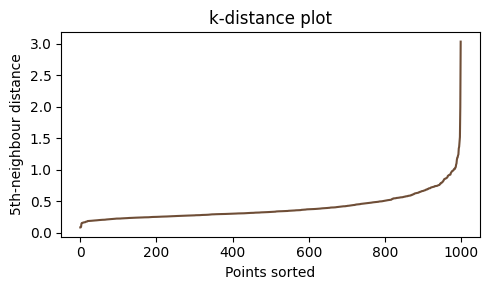

    eps  min_samples  clusters  noise
0   0.3            3        28    302
1   0.3            5        15    464
2   0.3            8         7    685
3   0.3           12         2    917
4   0.5            3         8     84
5   0.5            5         4    132
6   0.5            8         1    207
7   0.5           12         2    260
8   0.7            3         5     22
9   0.7            5         1     50
10  0.7            8         1     72
11  0.7           12         1     95
12  1.0            3         1      4
13  1.0            5         1      7
14  1.0            8         1     12
15  1.0           12         1     17


In [9]:
# References: [9][10][15] (full list at the end of the notebook)
# k-distance plot helps to choose eps (min_samples = 5)
d, _ = NearestNeighbors(n_neighbors=5).fit(Xs).kneighbors(Xs)
plt.figure(figsize=(5, 3)); plt.plot(np.sort(d[:, -1]), color="#6F4E37")
plt.xlabel("Points sorted"); plt.ylabel("5th-neighbour distance"); plt.title("k-distance plot")
plt.tight_layout(); plt.show()

rows = []
for eps in [0.3, 0.5, 0.7, 1.0]:
    for ms in [3, 5, 8, 12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)
        rows.append((eps, ms, len(set(lab) - {-1}), int((lab == -1).sum())))
grid = pd.DataFrame(rows, columns=["eps", "min_samples", "clusters", "noise"])
print(grid)

In [10]:
# References: [9][15] (full list at the end of the notebook)
EPS, MS = 0.7, 5
db_labels = DBSCAN(eps=EPS, min_samples=MS).fit_predict(Xs)
print(pd.Series(db_labels).value_counts().sort_index())
print("Noise points:", int((db_labels == -1).sum()))

-1     50
 0    950
Name: count, dtype: int64
Noise points: 50


**Sensitivity:** DBSCAN reacts strongly to `eps` and `min_samples` (see the grid). With small eps (0.3) most customers become noise and many tiny clusters appear; with eps=1.0 almost everything merges into one cluster. I chose **eps=0.7, min_samples=5** (50 noise points, 5 %), because it keeps one dense core and marks only the sparse edge as noise. DBSCAN finds **one dense group**, not four: the customers form a continuous cloud without density gaps, so K-Means groups are slices of that cloud. Noise is an algorithmic label, not proof of an error.

## 8. PCA, t-SNE and UMAP

Explained variance ratio: [0.355 0.329 0.316]
Cumulative: [0.355 0.684 1.   ]
     visits_per_week  order_price  wait_time
PC1             0.66        -0.59      -0.46
PC2             0.10        -0.54       0.83
Retained by 2 PCs: 0.684


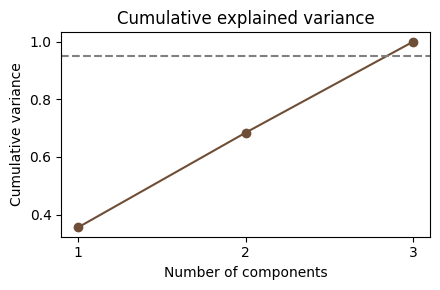

Components needed for 95 % of variance: 3


In [11]:
# References: [11][15] (full list at the end of the notebook)
pca_full = PCA().fit(Xs)
print("Explained variance ratio:", np.round(pca_full.explained_variance_ratio_, 3))
print("Cumulative:", np.round(np.cumsum(pca_full.explained_variance_ratio_), 3))
print(pd.DataFrame(pca_full.components_[:2], columns=features, index=["PC1", "PC2"]).round(2))

pca = PCA(n_components=2)
Xp = pca.fit_transform(Xs)
print("Retained by 2 PCs:", round(pca.explained_variance_ratio_.sum(), 3))

# Cumulative explained variance and the 95 % guideline from the lecture
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(4.5, 3))
plt.plot(range(1, 4), cum, marker="o", color="#6F4E37"); plt.axhline(0.95, ls="--", color="gray")
plt.xticks([1, 2, 3]); plt.xlabel("Number of components"); plt.ylabel("Cumulative variance")
plt.title("Cumulative explained variance"); plt.tight_layout(); plt.show()
pca95 = PCA(n_components=0.95).fit(Xs)
print("Components needed for 95 % of variance:", pca95.n_components_)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


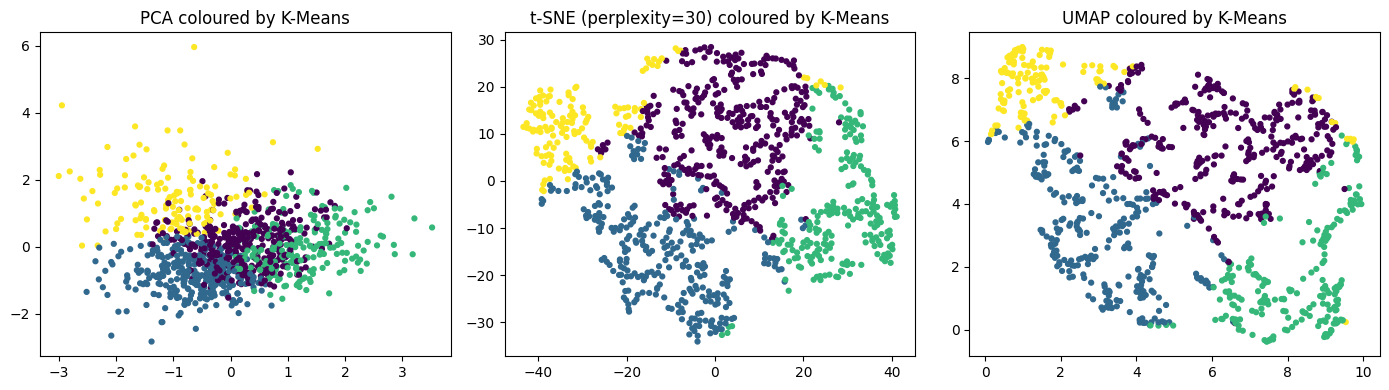

In [12]:
# References: [12][13][15] (full list at the end of the notebook)
Xt = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(Xs)

%pip -q install umap-learn
import umap
Xu = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(Xs)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, Z, name in zip(axes, [Xp, Xt, Xu], ["PCA", "t-SNE (perplexity=30)", "UMAP"]):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=km_labels, cmap="viridis", s=12)
    ax.set_title(name + " coloured by K-Means")
plt.tight_layout(); plt.show()

In [ ]:
# References: [12] (full list at the end of the notebook)
# Sensitivity of t-SNE to perplexity
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, p in zip(axes, [10, 50]):
    z = TSNE(n_components=2, perplexity=p, init="pca", learning_rate="auto", random_state=42).fit_transform(Xs)
    ax.scatter(z[:, 0], z[:, 1], c=km_labels, cmap="viridis", s=12); ax.set_title(f"t-SNE perplexity={p}")
plt.tight_layout(); plt.show()

**Comparison.** PCA keeps about **68 %** of variance in 2 components; the three features are nearly uncorrelated, so each component explains a similar share (0.36 / 0.33 / 0.32) and PCA compresses the data poorly. All **3** components are needed to reach the lecture's 95 % guideline, so there is nothing to compress here. PC1 mostly contrasts visits with price and wait time, PC2 is mainly wait time. t-SNE and UMAP preserve local neighbourhoods and show the groups as regions of one cloud; their distances and cluster sizes should not be read as true geometry, and t-SNE changes with perplexity. The visual separation is not an independent proof of cluster quality. *(Before submitting, add one sentence describing what you see in your own plots.)*

## 9. Isolation Forest and comparison with DBSCAN noise

In [ ]:
# References: [14][9][15] (full list at the end of the notebook)
flags = {}
for c in [0.02, 0.05, 0.10]:
    m = IsolationForest(contamination=c, random_state=42).fit(Xs)
    flags[c] = (m.predict(Xs) == -1)
    print(f"contamination={c}: flagged {int(flags[c].sum())}")

# Ranking by anomaly score (lower decision_function = more unusual)
iso = IsolationForest(contamination=0.05, random_state=42).fit(Xs)
scores = iso.decision_function(Xs)
top = np.argsort(scores)[:5]
print("Five most unusual customers (original units):")
print(X_imp.iloc[top].assign(score=scores[top].round(3)))

noise_mask = (db_labels == -1)
for c in flags:
    print(f"c={c}: overlap with DBSCAN noise = {int((noise_mask & flags[c]).sum())}, "
          f"disagreement = {int((noise_mask != flags[c]).sum())}")

plt.figure(figsize=(5.5, 4))
plt.scatter(Xp[:, 0], Xp[:, 1], c="lightgray", s=10)
plt.scatter(Xp[flags[0.05], 0], Xp[flags[0.05], 1], c="crimson", s=18, label="IsolationForest (0.05)")
plt.scatter(Xp[noise_mask, 0], Xp[noise_mask, 1], facecolors="none", edgecolors="navy", s=45, label="DBSCAN noise")
plt.legend(); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Flagged points in PCA view")
plt.tight_layout(); plt.show()

Isolation Forest with contamination 0.02 / 0.05 / 0.10 flags 20 / 50 / 100 customers, because contamination fixes the flagged share in advance (it is not a measured anomaly rate). With 0.05, **38 of its 50 flags coincide with DBSCAN noise**, and the 24 disagreements show that the two methods define "unusual" differently (isolation by random splits vs. low local density). A flagged customer is only unusual under the model; before calling it a real anomaly I would check the till/queue logs for recording errors and look at the customer's history.

## 10. Combined summary and post-hoc check
The Module 9 label is used here **only to look at the results afterwards**; it was not an input to any model above.

In [ ]:
# References: [17] (full list at the end of the notebook)
summary = pd.DataFrame({"kmeans_cluster": km_labels, "dbscan_cluster": db_labels,
                        "iforest_flag": flags[0.05].astype(int), "PC1": Xp[:, 0], "PC2": Xp[:, 1]})
print(summary.head())
print()
print("Share of customers who return next week, per K-Means cluster (post-hoc):")
print(hidden_label.groupby(km_labels).mean().round(3))

Post-hoc, the share of returning customers differs strongly between clusters (frequent visitors about 84 %, long-wait customers about 28 %). So the unsupervised groups agree with the Module 9 story: **frequent visits go with returning, long waits with not returning**. This is a consistency check, not ground truth: the label did not take part in clustering.

## 11. Conclusion, limitations, improvement
We analysed 1,000 synthetic customers and 3 numerical features (visits per week, order price, wait time; 5 % and 8 % missing values filled with the median). After standardization, K-Means suggested **K=4** groups (best silhouette about 0.27, stable across seeds). DBSCAN with eps=0.7 and min_samples=5 found **1 dense group and 50 noise points**, so the data look like a continuous cloud. The first two PCA components retained about **68 %** of variance. t-SNE and UMAP show local structure, subject to projection limits. Isolation Forest (contamination=0.05) flagged **50** customers, 38 of which are also DBSCAN noise.

**Limitations:** (1) the data are synthetic and generated by simple rules, so the findings describe the simulation, not real customers; (2) silhouette is low, so clusters are weakly separated and K=4 is a modelling choice, not a true number of groups.
**Improvement:** repeat on real coffee-shop transaction data with extra features (time of day, loyalty-card history) and validate clusters with a business metric.

None of the unsupervised outputs independently establishes a ground-truth class or a verified anomaly.

**Source:** synthetic data generated in this notebook (same generator as Module 9). Methods: scikit-learn (KMeans, DBSCAN, PCA, TSNE, IsolationForest), umap-learn.

## References
[1] Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
[2] Harris, C. R. et al. (2020). Array programming with NumPy. Nature, 585, 357-362. Random Generator: https://numpy.org/doc/stable/reference/random/generator.html
[3] pandas documentation: https://pandas.pydata.org/docs/
[4] Matplotlib documentation: https://matplotlib.org/stable/
[5] SimpleImputer: https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
[6] StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
[7] KMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html ; Lloyd, S. (1982). Least squares quantization in PCM. IEEE Transactions on Information Theory, 28(2), 129-137.
[8] silhouette_score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html ; Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.
[9] DBSCAN: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html ; Ester, M., Kriegel, H.-P., Sander, J., Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. KDD-96, 226-231.
[10] NearestNeighbors (k-distance plot): https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html
[11] PCA: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html ; Jolliffe, I. T., Cadima, J. (2016). Principal component analysis: a review and recent developments. Philosophical Transactions of the Royal Society A, 374, 20150202.
[12] TSNE: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html ; van der Maaten, L., Hinton, G. (2008). Visualizing data using t-SNE. Journal of Machine Learning Research, 9, 2579-2605.
[13] UMAP: https://umap-learn.readthedocs.io/en/latest/ ; McInnes, L., Healy, J., Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction. arXiv:1802.03426.
[14] IsolationForest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html ; Liu, F. T., Ting, K. M., Zhou, Z.-H. (2008). Isolation Forest. IEEE ICDM, 413-422.
[15] Course lecture "Discovering Hidden Structures" (AI Fundamentals).
[16] UCI Machine Learning Repository, Online Retail (id=352): https://archive.ics.uci.edu/dataset/352/online+retail (suggested starting point; not used because it has no wait-time feature).
[17] Own work: Module 9 notebook (same synthetic generator and seed 42).